# Introduction to Machine Translation (MT):

Machine Translation is a subfield of AI and linguistics that develops systems capable of translating text from one language to another. The primary goal of machine translation is to enable effective communication between people who speak different languages by automating the process of language translation.

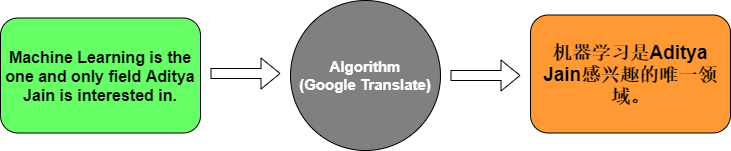

Challenges in Machine Translation:
- Ambiguity

Ex. I went to the bank.
- Idiomatic Expressions

Ex. It's raining cats and dogs.
- Low-Resource Languages

Some languages have very limited data.

Applications of Machine Translation:
- Global Business and E-commerce
-Cross-Cultural Communication
- Multilingual Content Creation
- Language Learning



## Neural Machine Translation:

Neural Machine Translation is a data-driven approach where a single large neural network learns to represent both the source language and the target language, and to directly map between them.
Instead of using manually defined rules or phrase tables, it learns translation patterns automatically from large datasets of bilingual text.

### Key Components of Neural Machine Translation:

<img src="https://drive.google.com/thumbnail?id=1xMmuMvOaYI73cYhQ1lbE5pIjDPWXhfgq&sz=w1000" width="600">


In [ ]:
#!pip install tensorflow

In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
import numpy as np

# Example bilingual dataset
english_sentences = ["Hello.", "How are you?", "This is a machine translation example."]
french_sentences = ["Bonjour.", "Comment ça va?", "Ceci est un exemple de traduction automatique."]

# Tokenize the english sentences
tokenizer_eng = Tokenizer()
tokenizer_eng.fit_on_texts(english_sentences) # Tokenize words and assign an integer ID to each unique word
eng_sequences = tokenizer_eng.texts_to_sequences(english_sentences) # Returns a list of tokens replaced by their index. Note: words index will start from 1 because 0 is reserved by default for padding (not assigned to any word).
print(f"eng_sequences = {eng_sequences}")
eng_word_index = tokenizer_eng.word_index # Returns the dictionary created by the tokenizer dict {word: index}.
print(f"eng_word_index = {eng_word_index}")

eng_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10]]
eng_word_index = {'hello': 1, 'how': 2, 'are': 3, 'you': 4, 'this': 5, 'is': 6, 'a': 7, 'machine': 8, 'translation': 9, 'example': 10}


In [ ]:
# Tokenize the french sentences
tokenizer_frn = Tokenizer()
tokenizer_frn.fit_on_texts(french_sentences)
frn_sequences = tokenizer_frn.texts_to_sequences(french_sentences)

print(f"frn_sequences = {frn_sequences}")
frn_word_index = tokenizer_frn.word_index
print(f"frn_word_index = {frn_word_index}")

frn_sequences = [[1], [2, 3, 4], [5, 6, 7, 8, 9, 10, 11]]
frn_word_index = {'bonjour': 1, 'comment': 2, 'ça': 3, 'va': 4, 'ceci': 5, 'est': 6, 'un': 7, 'exemple': 8, 'de': 9, 'traduction': 10, 'automatique': 11}


In [ ]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Padding sequences
eng_padded = pad_sequences(eng_sequences) # makes all sequences the same length by padding with zeros at the beginning (default)
print(f"eng_padded = {eng_padded}")

eng_padded = [[ 0  0  0  0  0  1]
 [ 0  0  0  2  3  4]
 [ 5  6  7  8  9 10]]


In [ ]:
frn_padded = pad_sequences(frn_sequences)
frn_padded

array([[ 0,  0,  0,  0,  0,  0,  1],
       [ 0,  0,  0,  0,  2,  3,  4],
       [ 5,  6,  7,  8,  9, 10, 11]], dtype=int32)

## LSTM Model

<img src="https://drive.google.com/uc?export=view&id=1rUaLO1wEOcUZ10Kwd0nUvS3jQzrqoOcI" width="550">

In [ ]:
from sklearn.model_selection import train_test_split

# Train-test split
eng_train, eng_test, frn_train, frn_test = train_test_split(eng_padded, frn_padded, test_size=0.2, random_state=42)

# Define the model
model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=len(eng_word_index) + 1, output_dim=64),
    tf.keras.layers.LSTM(64),
    tf.keras.layers.RepeatVector(frn_padded.shape[1]), #length of french sentence
    tf.keras.layers.LSTM(64, return_sequences=True),
    tf.keras.layers.TimeDistributed(tf.keras.layers.Dense(len(frn_word_index) + 1, activation='softmax')) #convert to probabilities for each frn word
])

model.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# Train the model
model.fit(eng_train, np.expand_dims(frn_train, -1), epochs=50, batch_size=1, validation_split=0.2)

# Evaluate the model
loss, accuracy = model.evaluate(eng_test, np.expand_dims(frn_test, -1))
print(f'Test Accuracy: {accuracy}')

Epoch 1/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step - accuracy: 0.1429 - loss: 2.4846 - val_accuracy: 0.0000e+00 - val_loss: 2.4882
Epoch 2/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 381ms/step - accuracy: 0.5714 - loss: 2.4762 - val_accuracy: 0.0000e+00 - val_loss: 2.4898
Epoch 3/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 178ms/step - accuracy: 0.5714 - loss: 2.4675 - val_accuracy: 0.0000e+00 - val_loss: 2.4915
Epoch 4/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step - accuracy: 0.5714 - loss: 2.4584 - val_accuracy: 0.0000e+00 - val_loss: 2.4935
Epoch 5/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 175ms/step - accuracy: 0.5714 - loss: 2.4483 - val_accuracy: 0.0000e+00 - val_loss: 2.4958
Epoch 6/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 346ms/step - accuracy: 0.5714 - loss: 2.4370 - val_accuracy: 0.0000e+00 - val_loss: 2.4983
Epoch 7/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 150ms/step - accuracy: 0.5714 - loss: 2.4240 - val_accuracy: 0.0000e+00 - val_loss: 2.5013
Epoch 8/50
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step - accuracy: 0.5714 - loss: 2.4089 - val_acc

In [ ]:
# Inference
def translate_sentence(sentence, model, eng_tokenizer, frn_tokenizer):
    sequence = eng_tokenizer.texts_to_sequences([sentence])
    padded_sequence = pad_sequences(sequence, maxlen=eng_padded.shape[1])
    predicted_sequence = model.predict(padded_sequence) #outputs probabilities for each timestep (french padded sentence) and each unique word in the target vocabulary.
    translated_sequence = np.argmax(predicted_sequence, axis=-1) #Returns the index (word ID) with the largest value at each timestep.
    translated_sentence = frn_tokenizer.sequences_to_texts(translated_sequence)
    return translated_sentence[0]

# Example Inference
input_sentence = "How are you?"
translated_sentence = translate_sentence(input_sentence, model, tokenizer_eng, tokenizer_frn)
print(f'Input: {input_sentence}\nTranslation: {translated_sentence}')

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 425ms/step
Input: How are you?
Translation: comment ça va


________________________________________________________________________________________________________________________________________

### Task 1: Understanding the Model Layers

Answer these simple questions in your own words:

1. What does the **Embedding** layer do to a word index?
3. What is the role of the **Encoder LSTM**?
5. What does the **Decoder LSTM** do?
8. Why do we use `softmax` in the final layer?


1. Embedding layer: It converts each word index into a dense numerical vector that represents the word’s meaning.
2. Encoder LSTM: It reads the input English sentence and captures its meaning and context in hidden states.
3. Decoder LSTM: It uses the encoder’s information to generate the French translation one word at a time.
4. Softmax: It converts the model’s output into probabilities for all possible words and selects the most likely next word.

### Task 2:

 Use Case: Language Translation (English-French)

A global e-commerce company wants to expand its reach to French-speaking customers and provide a seamless shopping experience. The company needs a language translation solution to automatically translate product listings, customer reviews, and other relevant content from English to French.

link: https://www.kaggle.com/datasets/devicharith/language-translation-englishfrench

In [2]:
from pathlib import Path

downloads = Path.home() / "Downloads"
list(downloads.glob("*french*")) + list(downloads.glob("*.zip"))

[PosixPath('/Users/ruqayahmohaimeed/Downloads/eng_-french.csv'),
 PosixPath('/Users/ruqayahmohaimeed/Downloads/InstallLDBPackage64c-2-1-5-00.zip'),
 PosixPath('/Users/ruqayahmohaimeed/Downloads/DisplayAuthors (2).zip'),
 PosixPath('/Users/ruqayahmohaimeed/Downloads/DisplayAuthors (3).zip'),
 PosixPath('/Users/ruqayahmohaimeed/Downloads/DisplayAuthors.zip'),
 PosixPath('/Users/ruqayahmohaimeed/Downloads/qader-ai-library.zip'),
 PosixPath('/Users/ruqayahmohaimeed/Downloads/db-derby-10.17.1.0-bin.zip'),
 PosixPath('/Users/ruqayahmohaimeed/Downloads/eclipse-jee-2025-03-R-win32-x86_64.zip'),
 PosixPath('/Users/ruqayahmohaimeed/Downloads/DisplayAuthors (1).zip'),
 PosixPath('/Users/ruqayahmohaimeed/Downloads/game_system_backup.zip')]

In [3]:
import pandas as pd

file_path = downloads / "eng_-french.csv"
df = pd.read_csv(file_path)
df.head()

,English words/sentences,French words/sentences
0,Hi.,Salut!
1,Run!,Cours !
2,Run!,Courez !
3,Who?,Qui ?
4,Wow!,Ça alors !


In [4]:
data = df[
    ["English words/sentences", "French words/sentences"]
].dropna().drop_duplicates()

data.columns = ["english", "french"]

data["english"] = data["english"].astype(str).str.strip().str.lower()
data["french"] = data["french"].astype(str).str.strip().str.lower()

data = data[
    (data["english"].str.split().str.len() <= 15) &
    (data["french"].str.split().str.len() <= 15)
]

data = data.sample(n=min(5000, len(data)), random_state=42).reset_index(drop=True)

print(data.shape)
data.head()

(5000, 2)


,english,french
0,"if you can digest them, raw vegetables are goo...","si on peut les digérer, les légumes crus font ..."
1,don't forget we have to do our homework.,n’oubliez pas qu'il nous faut faire nos devoirs.
2,don't be late for school.,ne soyez pas en retard à l'école.
3,he is in good physical condition.,il est en bonne condition physique.
4,we can fix this.,on peut corriger ça.


In [5]:
%pip install tensorflow

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.8/223.8 MB 7.3 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.6/12.6 MB 9.4 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 565.5/565.5 kB 5.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.4/2.4 MB 8.0 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 9.0 MB/s eta 0:00:00a 0:00:01m
  Attempting uninstall: protobuf━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  1/15 [libclang]
    Found existing installation: protobuf 5.29.3━━━━━━━━━━━━━━  1/15 [libclang]
    Uninstalling protobuf-5.29.3:━━━━━━━━━━━━━━━━━━━━━━━━━━━━━  1/15 [libclang]
      Successfully uninstalled protobuf-5.29.3━━━━━━━━━━━━━━━━  1/15 [libclang]
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15/15 [tensorflow]5 [tensorflow]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency confl

In [ ]:
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LENGTH = 15
MAX_VOCAB = 6000

eng_tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<unk>")
fr_tokenizer = Tokenizer(num_words=MAX_VOCAB, oov_token="<unk>")

eng_tokenizer.fit_on_texts(data["english"])
fr_tokenizer.fit_on_texts(data["french"])

eng_sequences = eng_tokenizer.texts_to_sequences(data["english"])
fr_sequences = fr_tokenizer.texts_to_sequences(data["french"])

eng_padded = pad_sequences(
    eng_sequences, maxlen=MAX_LENGTH,
    padding="post", truncating="post"
)

fr_padded = pad_sequences(
    fr_sequences, maxlen=MAX_LENGTH,
    padding="post", truncating="post"
)

print("English shape:", eng_padded.shape)
print("French shape:", fr_padded.shape)

In [1]:
%pip install --force-reinstall "tensorflow==2.20.0" "protobuf==5.28.3"

  Using cached absl_py-2.5.1-py3-none-any.whl.metadata (3.3 kB)
  Using cached astunparse-1.6.3-py2.py3-none-any.whl.metadata (4.4 kB)
  Using cached flatbuffers-25.12.19-py2.py3-none-any.whl.metadata (1.0 kB)
  Using cached gast-0.7.0-py3-none-any.whl.metadata (1.5 kB)
  Using cached google_pasta-0.2.0-py3-none-any.whl.metadata (814 bytes)
  Using cached libclang-18.1.1-1-py2.py3-none-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached opt_einsum-3.4.0-py3-none-any.whl.metadata (6.3 kB)
  Using cached termcolor-3.3.0-py3-none-any.whl.metadata (6.5 kB)
  Using cached typing_extensions-4.16.0-py3-none-any.whl.metadata (3.3 kB)
  Using cached grpcio-1.85.0-cp313-cp313-macosx_11_0_universal2.whl.metadata (3.8 kB)
  Using cached keras-3.15.1-py3-none-any.whl.metadata (6.4 kB)
  Using cached ml_dtypes-0.6.0-cp313-cp313-macosx_10_13_universal2.whl.metadata (8.8 kB)
  Using cached idna-3.20-py3-none-any.whl.metadata (7.2 kB)
  Using cached namex-0.1.0-py3-none-any.whl.metadata (322 bytes)


In [1]:
import torch
print(torch.__version__)

2.14.0


In [2]:
# Complete English-to-French Translation Model using PyTorch

import sys
import csv
import random
import subprocess
import importlib
import importlib.util
from pathlib import Path
from collections import Counter

# Install PyTorch automatically if it is not installed
if importlib.util.find_spec("torch") is None:
    print("Installing PyTorch... please wait")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "torch"])
    importlib.invalidate_caches()

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

random.seed(42)
torch.manual_seed(42)

# 1. Load the dataset
downloads = Path.home() / "Downloads"
file_path = downloads / "eng_-french.csv"

if not file_path.exists():
    files = list(downloads.glob("*french*.csv"))
    if not files:
        raise FileNotFoundError("The English-French CSV file was not found in Downloads.")
    file_path = files[0]

pairs = []
seen = set()

with open(file_path, "r", encoding="utf-8-sig", errors="replace", newline="") as file:
    reader = csv.DictReader(file)

    for row in reader:
        english = (row.get("English words/sentences") or "").strip().lower()
        french = (row.get("French words/sentences") or "").strip().lower()

        if (
            english and french
            and len(english.split()) <= 15
            and len(french.split()) <= 15
        ):
            pair = (english, french)

            if pair not in seen:
                seen.add(pair)
                pairs.append(pair)

random.shuffle(pairs)
pairs = pairs[:2000]

print("Number of sentence pairs:", len(pairs))

# 2. Build vocabularies
PAD, UNK, SOS, EOS = 0, 1, 2, 3
SPECIAL_WORDS = ["<pad>", "<unk>", "<sos>", "<eos>"]
MAX_VOCAB = 3000
SOURCE_LENGTH = 15
TARGET_LENGTH = 16

def build_vocabulary(sentences):
    counter = Counter(
        word
        for sentence in sentences
        for word in sentence.split()
    )

    words = [
        word for word, count in counter.most_common(MAX_VOCAB - 4)
        if word not in SPECIAL_WORDS
    ]

    index_to_word = SPECIAL_WORDS + words
    word_to_index = {
        word: index for index, word in enumerate(index_to_word)
    }

    return word_to_index, index_to_word

eng_word_to_index, eng_index_to_word = build_vocabulary(
    [english for english, french in pairs]
)

fr_word_to_index, fr_index_to_word = build_vocabulary(
    [french for english, french in pairs]
)

def encode_source(sentence):
    ids = [
        eng_word_to_index.get(word, UNK)
        for word in sentence.split()
    ][:SOURCE_LENGTH]

    return ([PAD] * (SOURCE_LENGTH - len(ids))) + ids

def encode_target(sentence):
    ids = [
        fr_word_to_index.get(word, UNK)
        for word in sentence.split()
    ][:TARGET_LENGTH - 1]

    decoder_input = [SOS] + ids
    decoder_output = ids + [EOS]

    decoder_input += [PAD] * (TARGET_LENGTH - len(decoder_input))
    decoder_output += [PAD] * (TARGET_LENGTH - len(decoder_output))

    return decoder_input, decoder_output

# 3. Split the dataset
split_point = int(len(pairs) * 0.8)
training_pairs = pairs[:split_point]
testing_pairs = pairs[split_point:]

def create_tensors(selected_pairs):
    source_data = []
    target_inputs = []
    target_outputs = []

    for english, french in selected_pairs:
        source_data.append(encode_source(english))
        decoder_input, decoder_output = encode_target(french)
        target_inputs.append(decoder_input)
        target_outputs.append(decoder_output)

    return (
        torch.tensor(source_data, dtype=torch.long),
        torch.tensor(target_inputs, dtype=torch.long),
        torch.tensor(target_outputs, dtype=torch.long)
    )

train_dataset = TensorDataset(*create_tensors(training_pairs))
test_dataset = TensorDataset(*create_tensors(testing_pairs))

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64)

print("Training examples:", len(training_pairs))
print("Testing examples:", len(testing_pairs))
print("English vocabulary:", len(eng_index_to_word))
print("French vocabulary:", len(fr_index_to_word))

# 4. Encoder-Decoder LSTM model
class TranslationModel(nn.Module):
    def __init__(self):
        super().__init__()

        self.eng_embedding = nn.Embedding(
            len(eng_index_to_word), 64, padding_idx=PAD
        )
        self.encoder = nn.LSTM(64, 128, batch_first=True)

        self.fr_embedding = nn.Embedding(
            len(fr_index_to_word), 64, padding_idx=PAD
        )
        self.decoder = nn.LSTM(64, 128, batch_first=True)

        self.output_layer = nn.Linear(
            128, len(fr_index_to_word)
        )

    def forward(self, source, target_input):
        source_embedding = self.eng_embedding(source)
        _, (hidden, cell) = self.encoder(source_embedding)

        target_embedding = self.fr_embedding(target_input)
        decoder_output, _ = self.decoder(
            target_embedding, (hidden, cell)
        )

        return self.output_layer(decoder_output)

device = torch.device("cpu")
model = TranslationModel().to(device)

print("\nModel architecture:")
print(model)

loss_function = nn.CrossEntropyLoss(ignore_index=PAD)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# 5. Train the model
EPOCHS = 5

for epoch in range(EPOCHS):
    model.train()
    total_loss = 0

    for source, target_input, target_output in train_loader:
        source = source.to(device)
        target_input = target_input.to(device)
        target_output = target_output.to(device)

        optimizer.zero_grad()

        predictions = model(source, target_input)

        loss = loss_function(
            predictions.reshape(-1, len(fr_index_to_word)),
            target_output.reshape(-1)
        )

        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    average_loss = total_loss / len(train_loader)
    print(f"Epoch {epoch + 1}/{EPOCHS} - Loss: {average_loss:.4f}")

# 6. Evaluate the model
model.eval()
correct = 0
total = 0

with torch.no_grad():
    for source, target_input, target_output in test_loader:
        predictions = model(
            source.to(device),
            target_input.to(device)
        ).argmax(dim=-1)

        target_output = target_output.to(device)
        mask = target_output != PAD

        correct += ((predictions == target_output) & mask).sum().item()
        total += mask.sum().item()

accuracy = correct / total
print(f"\nTest accuracy: {accuracy:.4f}")

# 7. Translate an English sentence
def translate_to_french(sentence):
    model.eval()

    source = torch.tensor(
        [encode_source(sentence.lower())],
        dtype=torch.long,
        device=device
    )

    with torch.no_grad():
        source_embedding = model.eng_embedding(source)
        _, (hidden, cell) = model.encoder(source_embedding)

        current_word = torch.tensor([[SOS]], device=device)
        translated_words = []

        for _ in range(TARGET_LENGTH):
            word_embedding = model.fr_embedding(current_word)

            decoder_output, (hidden, cell) = model.decoder(
                word_embedding, (hidden, cell)
            )

            logits = model.output_layer(decoder_output[:, -1, :])
            probabilities = torch.softmax(logits, dim=-1)
            next_word = int(probabilities.argmax(dim=-1).item())

            if next_word == EOS:
                break

            if next_word not in (PAD, SOS):
                translated_words.append(fr_index_to_word[next_word])

            current_word = torch.tensor([[next_word]], device=device)

    return " ".join(translated_words)

example_english, expected_french = testing_pairs[0]

print("\nEnglish:", example_english)
print("Expected French:", expected_french)
print("Model translation:", translate_to_french(example_english))

Number of sentence pairs: 2000
Training examples: 1600
Testing examples: 400
English vocabulary: 2718
French vocabulary: 3000

Model architecture:
TranslationModel(
  (eng_embedding): Embedding(2718, 64, padding_idx=0)
  (encoder): LSTM(64, 128, batch_first=True)
  (fr_embedding): Embedding(3000, 64, padding_idx=0)
  (decoder): LSTM(64, 128, batch_first=True)
  (output_layer): Linear(in_features=128, out_features=3000, bias=True)
)
Epoch 1/5 - Loss: 7.6367
Epoch 2/5 - Loss: 5.9713
Epoch 3/5 - Loss: 5.6952
Epoch 4/5 - Loss: 5.5632
Epoch 5/5 - Loss: 5.4461

Test accuracy: 0.1881

English: can you see the difference?
Expected French: peux-tu voir la différence ?
Model translation: je ne pas pas que vous pas
